# a. Preparation

### 1) Import Library

In [ ]:
!pip install gdown
!pip install scikit-learn
!pip install keras
!pip install tensorflow
!pip install seaborn

import os
import zipfile
import gdown
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import time
import psutil

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.decomposition import PCA as RandomizedPCA
from sklearn import svm
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
)

import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential, Model
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.metrics import Precision, Recall, F1Score
from keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    GlobalAveragePooling2D,
    Rescaling
)
from tensorflow.keras.layers import (
    RandomFlip,
    RandomRotation,
    RandomZoom,
    RandomContrast,
    RandomTranslation
)
from tensorflow.keras import layers, Model

### 2) Load Dataset

In [ ]:
# 1) Download image zip file from Google Drive
url = "https://drive.google.com/uc?id=1Xsfvg57L2j44AHAIomttWTlLlyzS_8Gf"
output = "waste_images.zip"
gdown.download(url, output, quiet=False)

# 2) Extract it into local folder
with zipfile.ZipFile(output, "r") as zip_ref:
    zip_ref.extractall("waste_images")

# 3) Set the base directory
base_dir = "waste_images"
images_dir = os.path.join(base_dir, "images")

Downloading...
From (original): https://drive.google.com/uc?id=1Xsfvg57L2j44AHAIomttWTlLlyzS_8Gf
From (redirected): https://drive.google.com/uc?id=1Xsfvg57L2j44AHAIomttWTlLlyzS_8Gf&confirm=t&uuid=1ff86a5b-c953-49fb-b6c5-f88a1bfa1e1d
To: /Users/meng/Desktop/CBS courses/semester_2/Machine & DeepLearning/ml_final_project/waste_images.zip
100%|██████████| 971M/971M [01:19<00:00, 12.3MB/s] 


### 3) Read Dataset

In [ ]:
# 1) Define a function to get image paths and labels
def read_files():
    images=[]
    labels=[]
    main_path=images_dir

    for category in os.listdir(main_path):
        if category != '.DS_Store': # .DS_Store is a default file of MAC OS file system in each folder. It needs to be excluded.

            # Every folder has 2 sub-folders: 'real_world' & 'default'. Collect images from both folders together
            for file in os.listdir(os.path.join(main_path,category,'real_world')):
                images.append(os.path.join(main_path,category,'real_world',file))
                labels.append(category)

            for file in os.listdir(os.path.join(main_path,category,'default')):
                images.append(os.path.join(main_path,category,'default',file))
                labels.append(category)

    return images,labels

In [ ]:
# 2) Read the data
images, labels = read_files()

# 3) Preview some data
images[:5], labels[:5]

(['waste_images/images/disposable_plastic_cutlery/real_world/Image_15.png',
  'waste_images/images/disposable_plastic_cutlery/real_world/Image_29.png',
  'waste_images/images/disposable_plastic_cutlery/real_world/Image_178.png',
  'waste_images/images/disposable_plastic_cutlery/real_world/Image_144.png',
  'waste_images/images/disposable_plastic_cutlery/real_world/Image_150.png'],
 ['disposable_plastic_cutlery',
  'disposable_plastic_cutlery',
  'disposable_plastic_cutlery',
  'disposable_plastic_cutlery',
  'disposable_plastic_cutlery'])

### 4) GPU Tracking (if GPUs enable)

In [ ]:
def get_gpu_memory():
    gpus = tf.config.list_physical_devices('GPU')
    if gpus:
        try:
            info = tf.config.experimental.get_memory_info(gpus[0].name)
            return info['current']  # in bytes
        except:
            return None
    return None

# b. EDA

### 1) Basic Information

In [ ]:
# check the number of images
print(f"Number of images: {len(images)}")

# check the number of labels
print(f"Number of labels: {len(labels)}")

# check the number of unique labels
print(f"Number of unique labels: {len(set(labels))}")

# check the name of the labels
print(f"Labels: {set(labels)}")

Number of images: 15000
Number of labels: 15000
Number of unique labels: 30
Labels: {'eggshells', 'glass_food_jars', 'glass_cosmetic_containers', 'aluminum_soda_cans', 'tea_bags', 'plastic_cup_lids', 'styrofoam_cups', 'styrofoam_food_containers', 'aluminum_food_cans', 'food_waste', 'coffee_grounds', 'aerosol_cans', 'plastic_shopping_bags', 'paper_cups', 'plastic_trash_bags', 'plastic_detergent_bottles', 'plastic_straws', 'steel_food_cans', 'cardboard_packaging', 'clothing', 'plastic_water_bottles', 'shoes', 'plastic_soda_bottles', 'newspaper', 'plastic_food_containers', 'cardboard_boxes', 'magazines', 'disposable_plastic_cutlery', 'office_paper', 'glass_beverage_bottles'}


In [ ]:
# Check the size of each image
# 1) Create a function to return the image size
def check_image_sizes(folder_path):
    image_sizes = {}

    for root, dirs, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".gif")):
                image_path = os.path.join(root, file)
                with Image.open(image_path) as img:
                    width, height = img.size
                    if (width, height) in image_sizes:
                        image_sizes[(width, height)].append(image_path)
                    else:
                        image_sizes[(width, height)] = [image_path]

    return image_sizes

# 2) Apply the imgae size checking function
image_sizes = check_image_sizes(images_dir)

# 3) Print the image size
print("IMAGE SIZES:")
for size, images in image_sizes.items():
    print(f"Size: {size}, Number of Images: {len(images)}")

IMAGE SIZES:
Size: (256, 256), Number of Images: 15000


### 2) Data Distribution

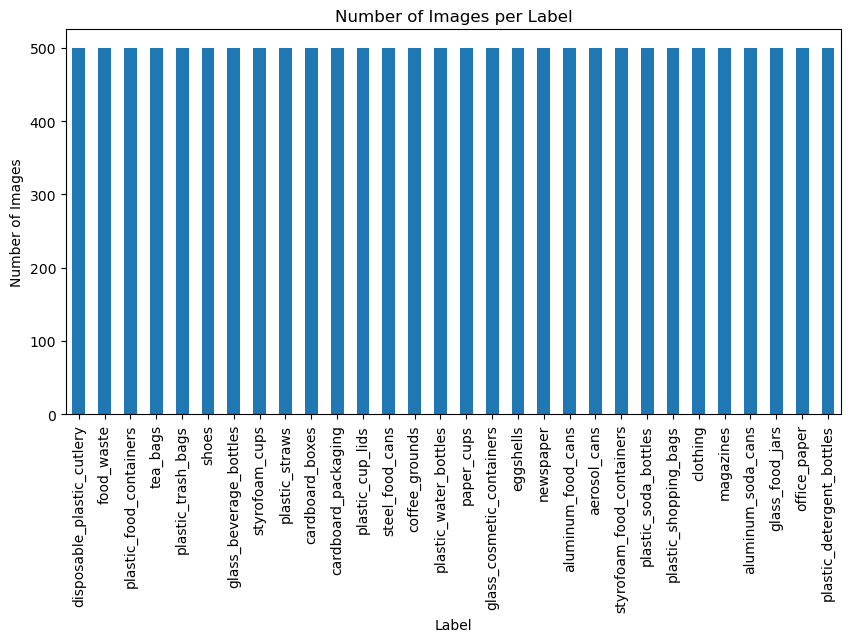

In [ ]:
# Plot the amount of images per label to check if the data is balanced

def plot_images_per_label(labels):
    label_counts = pd.Series(labels).value_counts()
    plt.figure(figsize=(10, 5))
    label_counts.plot(kind='bar')
    plt.title('Number of Images per Label')
    plt.xlabel('Label')
    plt.ylabel('Number of Images')
    plt.show()

plot_images_per_label(labels)

### 3) Random Image Check

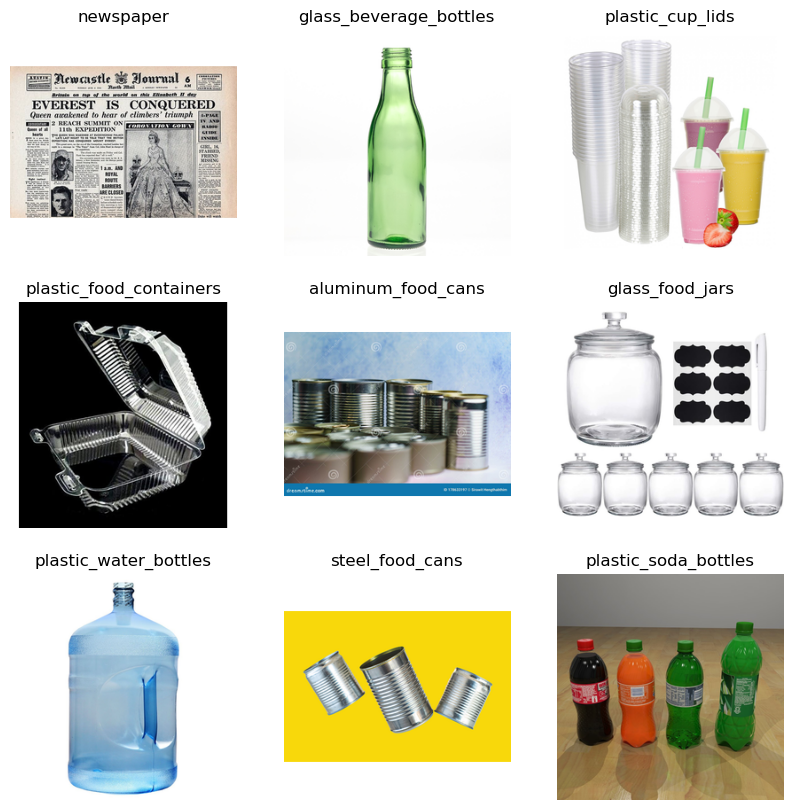

In [ ]:
# Plot random images
def plot_random_images(images, labels):
    random_indices = np.random.choice(len(images), 9, replace=False)
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        img = tf.keras.preprocessing.image.load_img(images[random_indices[i]], target_size=(256, 256))
        plt.imshow(img)
        plt.title(labels[random_indices[i]])
        plt.axis('off')
    plt.show()

plot_random_images(images, labels)


# c. Models

## 1. SVM (Baseline Model)

###  SVM (Baseline Model) - Prepare the Dataset

In [ ]:
# Load the images and labels
X = []
y = []

for i in range(len(images)):
    img = keras.utils.load_img(images[i], target_size=(32,32))
    img = keras.utils.img_to_array(img)
    X.append(img)
    y.append(labels[i])

In [ ]:
# Convert the images to numpy array
X = np.array(X)
# Convert the labels to numpy array
y = np.array(y)

# Check the shape of the images
print(f"Shape of images: {X.shape}")
# Check the shape of the labels
print(f"Shape of labels: {y.shape}")

Shape of images: (15000, 32, 32, 3)
Shape of labels: (15000,)


In [ ]:
# Encode the labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# check the shape of the encoded labels
print(f"Shape of encoded labels: {y_encoded.shape}")
# check the number of unique labels
print(f"Number of unique labels: {len(set(y_encoded))}")

Shape of encoded labels: (15000,)
Number of unique labels: 30


In [ ]:
# Split the data into train, test and validation sets
# 70% training, 15% testing, 15% validation
X_train, X_temp, y_train, y_temp = train_test_split(X, y_encoded, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Check the shape of the train, test and validation sets
print(f"Shape of training set: {X_train.shape}")
print(f"Shape of testing set: {X_test.shape}")
print(f"Shape of validation set: {X_val.shape}")

Shape of training set: (10500, 32, 32, 3)
Shape of testing set: (2250, 32, 32, 3)
Shape of validation set: (2250, 32, 32, 3)


###  SVM (Baseline Model) - Pre-processing

In [ ]:
# Pre-process the data
# 1) Normalize image pixels
X_train_svm = X_train.astype('float32') / 255.0
X_val_svm = X_val.astype('float32') / 255.0
X_test_svm = X_test.astype('float32') / 255.0

# 2-1) Flatten images
X_train_svm = X_train_svm.reshape(X_train_svm.shape[0], -1)
X_val_svm = X_val_svm.reshape(X_val_svm.shape[0], -1)
X_test_svm = X_test_svm.reshape(X_test_svm.shape[0], -1)

# 2-2) Check the shape of the images after flattening
print(f"Shape of training set after flattening: {X_train_svm.shape}")
print(f"Shape of testing set after flattening: {X_test_svm.shape}")
print(f"Shape of validation set after flattening: {X_val_svm.shape}")

Shape of training set after flattening: (10500, 3072)
Shape of testing set after flattening: (2250, 3072)
Shape of validation set after flattening: (2250, 3072)


In [ ]:
# 3) Scale images
scaler = StandardScaler()
X_train_svm = scaler.fit_transform(X_train_svm)
X_val_svm = scaler.transform(X_val_svm)
X_test_svm = scaler.transform(X_test_svm)

###  SVM (Baseline Model) - Building the Model

In [ ]:
# Use principal component analysis to extract 150 fundamental components
pca = RandomizedPCA(n_components=300, whiten=True, random_state=42)

# Instantiate SVC model with 'rbf' kernel
svc = svm.SVC(kernel="rbf", class_weight="balanced")

# Combine them into a pipeline
model = make_pipeline(pca, svc)

In [ ]:
# Tune SVM hyperparameters using GridSearchCV
# 1) Set testing parameters for GridSearchCV
param_grid = {"svc__C": [1, 5, 10, 50], "svc__gamma": ['scale', 0.01, 0.001]}

# 2) Apply GridSearchCV function
grid = GridSearchCV(model, param_grid, cv=5, n_jobs=-1, verbose=2)

###  SVM (Baseline Model) - Training the Model

In [ ]:
# Train the model
# 1) Record memory usage before training
mem_before_svm = psutil.virtual_memory().used
#gpu_mem_before_svm = get_gpu_memory()

# 2) Record training start time
start_time_svm = time.time()

# 3) Fit the data into SVM model in GridSearchCV
grid.fit(X_train_svm, y_train)
print("Best parameters:", grid.best_params_)

# 4) Record training end time
end_time_svm = time.time()

# 5) Record memory usage after training
mem_after_svm = psutil.virtual_memory().used
#gpu_mem_after_svm = get_gpu_memory()

Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END .........................svc__C=1, svc__gamma=scale; total time=  30.3s
[CV] END .........................svc__C=1, svc__gamma=scale; total time=  30.5s
[CV] END .........................svc__C=1, svc__gamma=scale; total time=  30.5s
[CV] END .........................svc__C=1, svc__gamma=scale; total time=  30.6s
[CV] END .........................svc__C=1, svc__gamma=scale; total time=  30.8s
[CV] END ..........................svc__C=1, svc__gamma=0.01; total time=  31.2s
[CV] END ..........................svc__C=1, svc__gamma=0.01; total time=  31.4s
[CV] END ..........................svc__C=1, svc__gamma=0.01; total time=  31.8s
[CV] END ..........................svc__C=1, svc__gamma=0.01; total time=  31.8s
[CV] END ..........................svc__C=1, svc__gamma=0.01; total time=  31.2s
[CV] END .........................svc__C=1, svc__gamma=0.001; total time=  30.1s
[CV] END .........................svc__C=1, svc_

In [ ]:
# 6) Training time used
train_duration_svm = end_time_svm - start_time_svm
print(f"Training Time: {train_duration_svm:.2f} sec")

# 7) CPU & GPU usage
mem_used_svm = (mem_after_svm - mem_before_svm) / 1024**2  # MB
print(f"CPU Memory Used for Training: {mem_used_svm:.2f} MB")

# if gpu_mem_before_svm is not None and gpu_mem_after_svm is not None:
#   gpu_mem_used_svm = (gpu_mem_after_svm - gpu_mem_before_svm) / 1024**2  # MB

#   print(f"GPU Memory Used for Training: {gpu_mem_used_svm:.2f} MB")

# else:
#   print("GPU memory info not available.")

Training Time: 215.17 sec
CPU Memory Used for Training: -825.91 MB


###  SVM (Baseline Model) - Making Predictions

In [ ]:
# Predictions
model = grid.best_estimator_
y_pred = model.predict(X_test_svm)

###  SVM (Baseline Model) - Evaluating the model

In [ ]:
# 1) Classification Report
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.72      0.68      0.70        75
           1       0.31      0.39      0.34        70
           2       0.49      0.56      0.52        75
           3       0.35      0.36      0.35        70
           4       0.29      0.33      0.31        67
           5       0.25      0.42      0.32        78
           6       0.71      0.68      0.70        95
           7       0.71      0.56      0.63        80
           8       0.46      0.69      0.55        54
           9       0.64      0.77      0.70        66
          10       0.70      0.64      0.67        75
          11       0.60      0.57      0.58        74
          12       0.69      0.53      0.60        75
          13       0.41      0.74      0.53        78
          14       0.32      0.46      0.37        70
          15       0.48      0.36      0.41        83
          16       0.70      0.51      0.59        77
          17       0.63    

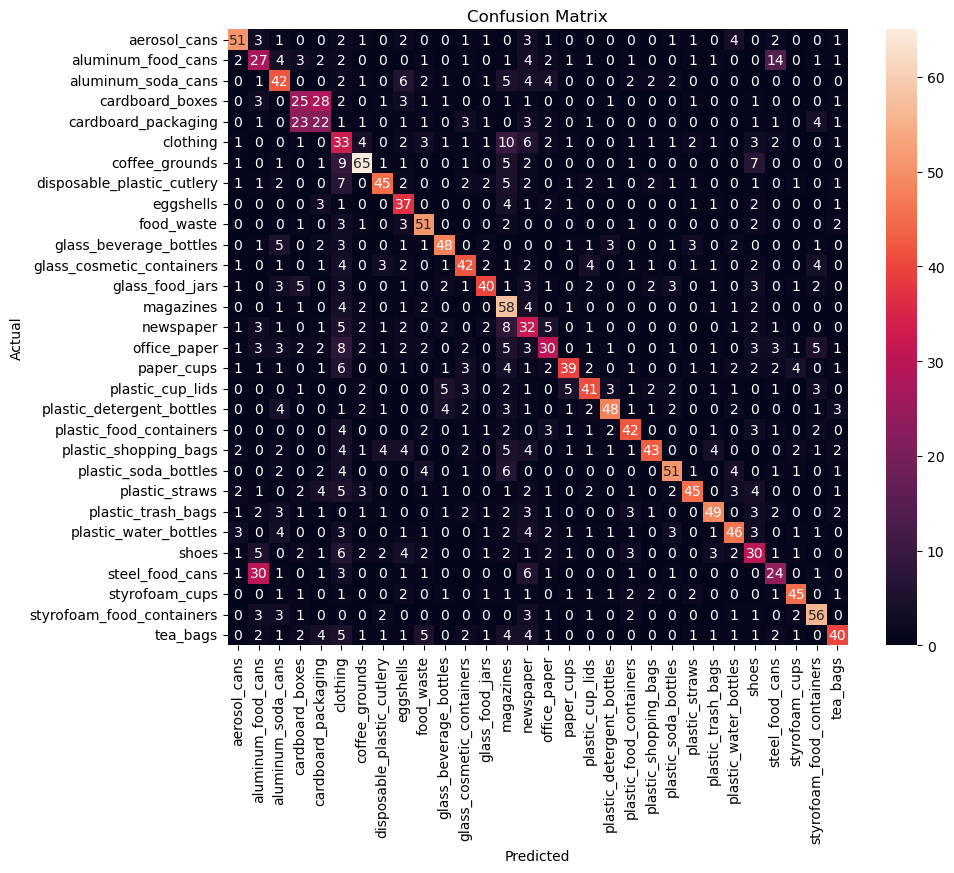

In [ ]:
# 2) Confusion Matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt="d", xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## 2. CNN

###  CNN - Prepare the Dataset

In [ ]:
# 1) Get main image dir and categories
path = os.path.join("waste_images", "images")
categories = os.listdir(path)

print(f"Path: {path}")
print(f"Categories: {categories}")

Path: waste_images/images
Categories: ['disposable_plastic_cutlery', 'food_waste', '.DS_Store', 'office_paper', 'glass_food_jars', 'aluminum_soda_cans', 'magazines', 'clothing', 'plastic_shopping_bags', 'plastic_soda_bottles', 'styrofoam_food_containers', 'aerosol_cans', 'aluminum_food_cans', 'newspaper', 'eggshells', 'glass_cosmetic_containers', 'paper_cups', 'plastic_water_bottles', 'coffee_grounds', 'steel_food_cans', 'plastic_cup_lids', 'cardboard_packaging', 'cardboard_boxes', 'plastic_straws', 'styrofoam_cups', 'glass_beverage_bottles', 'shoes', 'plastic_trash_bags', 'tea_bags', 'plastic_food_containers', 'plastic_detergent_bottles']


In [ ]:
# 2) Define the batch size and image size
BATCH_SIZE = 32
IMG_SIZE = (256, 256)

# 3) Define the training dataset
train = image_dataset_from_directory(
    path,
    labels='inferred',  # Automatically infers labels from subdirectory names
    label_mode='categorical',  # Return labels as one-hot encoded vectors
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    validation_split=0.3,  # 30% for validation
    subset='training',
    seed=42
)

class_names = train.class_names

# 4) Define the temporary validation dataset
temp_validation = image_dataset_from_directory(
    path,
    labels='inferred',  # Automatically infers labels from subdirectory names
    label_mode='categorical',  # Return labels as one-hot encoded vectors
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE,
    validation_split=0.3,  # 30% for validation
    subset='validation',
    seed=42
)

# 5) Split the temporary validation dataset into validation and test datasets
# Define the ratio for splitting the temporary validation dataset
val_ratio = 0.5
val_size = int(len(temp_validation) * val_ratio)

# Split the the temporary validation dataset
validation = temp_validation.take(val_size)
test = temp_validation.skip(val_size)

# Auto-tune the dataset for training performance by using pre-fetch
AUTOTUNE = tf.data.experimental.AUTOTUNE
train = train.prefetch(buffer_size=AUTOTUNE)

Found 15000 files belonging to 30 classes.
Using 10500 files for training.
Found 15000 files belonging to 30 classes.
Using 4500 files for validation.


###  CNN - Pre-processing

In [ ]:
# 1) Data augmentation and normalize image pixels for training dataset ONLY
# Define the data augmentation layers
data_augmentation = tf.keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    # Disabled the following items because they'll lower accuracy
    # keras.layers.RandomRotation(0.05),
    # keras.layers.RandomZoom(0.05),
    # keras.layers.RandomContrast(0.05),
    # keras.layers.RandomBrightness(0.02)
], name="data_augmentation")

# Define pre-processing function with augmentation
def process_image_augmented(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = data_augmentation(image)

    return image, label

# Apply pre-processing function on training dataset
train_cnn = train.map(process_image_augmented, num_parallel_calls=AUTOTUNE)

In [ ]:
# 2) Normalize image pixels for validation and test datasets
validation_cnn = validation.map(lambda x, y: (x / 255.0, y))
test_cnn = test.map(lambda x, y: (x / 255.0, y))

###  CNN - Building the Model

In [ ]:
# Input layer
input = keras.layers.Input(shape=(256, 256, 3), name='input_layer')

# 1st Convolutional Block (32 filters)
# - Conv2D scans images for patterns -> to extract features
# - MaxPooling2D reduces imgae sizes -> to keep the strongest features

x = keras.layers.Conv2D(filters=32, kernel_size=(3, 3), activation='relu', padding='same', name='conv1')(input)
# filter x 32; kernal (filter) size (3, 3)
# activation='relu' -> Rectifies liner Unit, output range [0, ∞); all negatives -> 0 & keep all positives
# padding='same' -> keep paddings = keep original image size, otherwise the image size will be reduced after Conv2D
# if not keeping the original image size -> output_size = input_size − kernel_size + 1

x = keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool1')(x)
# reduced size (2, 2) -> halfen the size

# 2nd Convolutional Block (64 filters)
x = keras.layers.Conv2D(filters=64, kernel_size=(3, 3), activation='relu', padding='same', name='conv2')(x)
x = keras.layers.MaxPooling2D(pool_size=(2, 2), name='pool2')(x)

# Flatten Layer
x = keras.layers.Flatten(name='flatten')(x)

# Dense Layer
x = keras.layers.Dense(units=128, activation='relu', name='dense1')(x)

# Output Logits layer (30 units for 30 waste categories)
output_logits = keras.layers.Dense(units=30, name='output_logits')(x)

# Separate Softmax Layer - Turn values into probabilities; sum = 1
output_softmax = keras.layers.Softmax(name='output_softmax')(output_logits)

# Build the Model
base_cnn_model = keras.Model(inputs=input, outputs=output_softmax, name='baseline_cnn')

# Print Model summary
base_cnn_model.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 262144)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense1 (Dense)                  │ (None, 128)            │    33,554,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_logits (Dense)           │ (None, 30)             │         3,870 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_softmax (Softmax)        │ (None, 30)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,577,822 (128.09 MB)

 Trainable params: 33,577,822 (128.09 MB)

 Non-trainable params: 0 (0.00 B)

###  CNN - Compiling the Model

In [ ]:
# Compile the model
base_cnn_model.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = [
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall'),
        F1Score(name='f1_score', average='macro'
        ),
    ]
)

###  CNN - Training the Model

In [ ]:
# Train the model
# 1) Record memory usage before training
mem_before_base_cnn = psutil.virtual_memory().used
# gpu_mem_before_base_cnn = get_gpu_memory()

# 2) Record training start time
start_time_base_cnn = time.time()

# 3) Fit the data into base CNN model
history = base_cnn_model.fit(
    train_cnn,                         # Training Dataset
    validation_data = validation_cnn,  # Validation Dataset
    epochs = 10,                       # Number of epochs for training
    verbose = 1                        # Showing training progress
)

# 4) Record training end time
end_time_base_cnn = time.time()

# 5) Record memory usage after training
mem_after_base_cnn = psutil.virtual_memory().used
# gpu_mem_after_base_cnn = get_gpu_memory()

Epoch 1/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.1084 - f1_score: 0.0966 - loss: 5.1009 - precision: 0.2407 - recall: 0.0135

2025-05-05 16:13:15.390091: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 39s 113ms/step - accuracy: 0.1086 - f1_score: 0.0968 - loss: 5.0957 - precision: 0.2415 - recall: 0.0135 - val_accuracy: 0.2920 - val_f1_score: 0.2794 - val_loss: 2.6148 - val_precision: 0.7097 - val_recall: 0.1080
Epoch 2/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 37s 111ms/step - accuracy: 0.3782 - f1_score: 0.3737 - loss: 2.2619 - precision: 0.7800 - recall: 0.1754 - val_accuracy: 0.4112 - val_f1_score: 0.4078 - val_loss: 2.1963 - val_precision: 0.7230 - val_recall: 0.2540
Epoch 3/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.5989 - f1_score: 0.5984 - loss: 1.5149 - precision: 0.8418 - recall: 0.4180

2025-05-05 16:14:29.630779: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 37s 113ms/step - accuracy: 0.5990 - f1_score: 0.5985 - loss: 1.5145 - precision: 0.8419 - recall: 0.4182 - val_accuracy: 0.4643 - val_f1_score: 0.4649 - val_loss: 2.1815 - val_precision: 0.7122 - val_recall: 0.3558
Epoch 4/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 37s 112ms/step - accuracy: 0.7196 - f1_score: 0.7183 - loss: 1.0540 - precision: 0.8758 - recall: 0.5999 - val_accuracy: 0.4857 - val_f1_score: 0.4854 - val_loss: 2.3542 - val_precision: 0.6452 - val_recall: 0.4067
Epoch 5/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step - accuracy: 0.8099 - f1_score: 0.8082 - loss: 0.6850 - precision: 0.9087 - recall: 0.7335

2025-05-05 16:15:44.930111: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 38s 115ms/step - accuracy: 0.8100 - f1_score: 0.8082 - loss: 0.6849 - precision: 0.9087 - recall: 0.7336 - val_accuracy: 0.5384 - val_f1_score: 0.5360 - val_loss: 2.2912 - val_precision: 0.6780 - val_recall: 0.4701
Epoch 6/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 36s 110ms/step - accuracy: 0.8540 - f1_score: 0.8525 - loss: 0.5526 - precision: 0.9238 - recall: 0.7981 - val_accuracy: 0.5357 - val_f1_score: 0.5352 - val_loss: 2.5726 - val_precision: 0.6408 - val_recall: 0.4835
Epoch 7/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.8896 - f1_score: 0.8892 - loss: 0.4089 - precision: 0.9373 - recall: 0.8529

2025-05-05 16:16:58.351685: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 37s 112ms/step - accuracy: 0.8897 - f1_score: 0.8892 - loss: 0.4088 - precision: 0.9373 - recall: 0.8529 - val_accuracy: 0.5353 - val_f1_score: 0.5330 - val_loss: 2.7448 - val_precision: 0.6212 - val_recall: 0.5000
Epoch 8/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 38s 115ms/step - accuracy: 0.9096 - f1_score: 0.9074 - loss: 0.3550 - precision: 0.9408 - recall: 0.8757 - val_accuracy: 0.5647 - val_f1_score: 0.5625 - val_loss: 2.6226 - val_precision: 0.6501 - val_recall: 0.5259
Epoch 9/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.9309 - f1_score: 0.9283 - loss: 0.2817 - precision: 0.9508 - recall: 0.9083

2025-05-05 16:18:13.883945: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 38s 115ms/step - accuracy: 0.9309 - f1_score: 0.9283 - loss: 0.2817 - precision: 0.9508 - recall: 0.9083 - val_accuracy: 0.5732 - val_f1_score: 0.5680 - val_loss: 2.7360 - val_precision: 0.6502 - val_recall: 0.5393
Epoch 10/10
329/329 ━━━━━━━━━━━━━━━━━━━━ 38s 114ms/step - accuracy: 0.9418 - f1_score: 0.9398 - loss: 0.2284 - precision: 0.9572 - recall: 0.9252 - val_accuracy: 0.5710 - val_f1_score: 0.5688 - val_loss: 3.1352 - val_precision: 0.6302 - val_recall: 0.5509


In [ ]:
# 6) Training time used
train_duration_base_cnn = end_time_base_cnn - start_time_base_cnn
print(f"Training Time: {train_duration_base_cnn:.2f} sec")

# 7) CPU & GPU usage
mem_used_base_cnn = (mem_after_base_cnn - mem_before_base_cnn) / 1024**2  # MB
print(f"CPU Memory Used for Training: {mem_used_base_cnn:.2f} MB")

# if gpu_mem_before_base_cnn is not None and gpu_mem_after_base_cnn is not None:
#   gpu_mem_used_base_cnn = (gpu_mem_after_base_cnn - gpu_mem_before_base_cnn) / 1024**2  # MB

#   print(f"GPU Memory Used for Training: {gpu_mem_used_svm:.2f} MB")

# else:
#   print("GPU memory info not available.")

Training Time: 375.04 sec
CPU Memory Used for Training: 938.56 MB


###  CNN - Evaluating the Model

In [ ]:
# Evaluate the model with test dataset
loss, accuracy, precision, recall, f1_score = base_cnn_model.evaluate(test_cnn)
print(f"Test Loss for Baseline CNN Model: {loss:.4f}")
print(f"Test Accuracy for Baseline CNN Model: {accuracy * 100:.2f}%")
print(f"Test Precision for Baseline CNN Model: {precision:.4f}")
print(f"Test Recall for Baseline CNN Model: {recall:.4f}")
print(f"Test F1 Score for Baseline CNN Model: {f1_score:.4f}")

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - accuracy: 0.5676 - f1_score: 0.5571 - loss: 3.1386 - precision: 0.6265 - recall: 0.5447
Test Loss for Baseline CNN Model: 3.0669
Test Accuracy for Baseline CNN Model: 58.50%
Test Precision for Baseline CNN Model: 0.6417
Test Recall for Baseline CNN Model: 0.5681
Test F1 Score for Baseline CNN Model: 0.5873


In [ ]:
# Plot the training and validation accuracy
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(10)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy for Baseline CNN')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss for Baseline CNN')
plt.legend(loc='upper right')

plt.show()

## 3. CNN(Residual Connection)

### CNN(Residual Connection and SE-block) - Building the Model

In [ ]:
# Input
inp = keras.layers.Input((256, 256, 3), name='input_layer')

# --- Block 1 + 2 with residual ---
# conv1 → act1 → pool1
x = layers.Conv2D(32, (3, 3), padding='same', name='conv1')(inp)
x = layers.Activation('relu', name='act1')(x)
p1 = layers.MaxPooling2D((2, 2), name='pool1')(x)

# conv2 → act2
x = layers.Conv2D(64, (3, 3), padding='same', name='conv2')(p1)
x = layers.Activation('relu', name='act2')(x)

# Projection of p1 → match channels(64)
skip1 = layers.Conv2D(64, (1, 1), padding='same', name='proj1')(p1)

# Add residual
x = layers.Add(name='residual_add1')([x, skip1])

# pool2
x = layers.MaxPooling2D((2, 2), name='pool2')(x)

# --- Block 3 + 4 with residual ---
# conv3 → act3 → pool3
x = layers.Conv2D(128, (3, 3), padding='same', name='conv3')(x)
x = layers.Activation('relu', name='act3')(x)
p3 = layers.MaxPooling2D((2, 2), name='pool3')(x)

# conv4 → act4
x = layers.Conv2D(128, (3, 3), padding='same', name='conv4')(p3)
x = layers.Activation('relu', name='act4')(x)

# Projection of p3 → match channels(128)
skip2 = layers.Conv2D(128, (1, 1), padding='same', name='proj2')(p3)

# Add residual
x = layers.Add(name='residual_add2')([x, skip2])

# pool4
x = layers.MaxPooling2D((2, 2), name='pool4')(x)

# --- Classification head ---
x = layers.Flatten(name='flatten')(x)
x = layers.Dense(128, activation='relu', name='dense1')(x)
x = layers.Dropout(0.5, name='dropout1')(x)
logits = layers.Dense(30, name='output_logits')(x)
out = layers.Softmax(name='output_softmax')(logits)

# Build model
residual_model = Model(inputs=inp, outputs=out, name='residual_cnn')
residual_model.summary()

Model: "residual_cnn_no_SE"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1 (Conv2D)      │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act1 (Activation)   │ (None, 256, 256,  │          0 │ conv1[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 128, 128,  │          0 │ act1[0][0]        │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2 (Conv2D)      │ (None, 128, 128,  │     18,496 │ pool1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act2 (Activation)   │ (None, 128, 128,  │          0 │ conv2[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj1 (Conv2D)      │ (None, 128, 128,  │      2,112 │ pool1[0][0]       │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_add1 (Add) │ (None, 128, 128,  │          0 │ act2[0][0],       │
│                     │ 64)               │            │ proj1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool2               │ (None, 64, 64,    │          0 │ residual_add1[0]… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv3 (Conv2D)      │ (None, 64, 64,    │     73,856 │ pool2[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act3 (Activation)   │ (None, 64, 64,    │          0 │ conv3[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool3               │ (None, 32, 32,    │          0 │ act3[0][0]        │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv4 (Conv2D)      │ (None, 32, 32,    │    147,584 │ pool3[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ act4 (Activation)   │ (None, 32, 32,    │          0 │ conv4[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ proj2 (Conv2D)      │ (None, 32, 32,    │     16,512 │ pool3[0][0]       │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ residual_add2 (Add) │ (None, 32, 32,    │          0 │ act4[0][0],       │
│                     │ 128)              │            │ proj2[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool4               │ (None, 16, 16,    │          0 │ residual_add2[0]

 Total params: 4,457,758 (17.00 MB)

 Trainable params: 4,457,758 (17.00 MB)

 Non-trainable params: 0 (0.00 B)

### CNN(Residual Connection and SE-block) - Compile the Model

In [ ]:
# compile the model
residual_model.compile(
    optimizer = 'adam',
    loss = 'categorical_crossentropy',
    metrics = [
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall'),
        F1Score(name='f1_score', average='macro')
    ]
)
# Define early stopping
# early_stop = EarlyStopping(
#     monitor = 'val_loss',  # Training shops when the validation error reaches its minimum values
#     patience = 3,  # Stopping the training if no improvements shown after 3 epochs
#     restore_best_weights = True)
# # Define reduce LROn plateau
# reduce_lr = ReduceLROnPlateau(
#     monitor = 'val_loss',
#     factor = 0.5,
#     patience = 2,  # Adjusting learning rate max. twice
#     min_lr = 1e-6,
#     verbose = 1)

### CNN(Residual Connection) - Training the Model

In [ ]:
# Train the model
# 1) Record memory usage before training
mem_before_residaul_cnn = psutil.virtual_memory().used

# 2) Record training start time
start_time_residual_cnn = time.time()

# 3) fit the model
history_residual = residual_model.fit(
    train_cnn,
    validation_data = validation_cnn,
    epochs = 30,  # Increased from 10 to 30
    verbose = 1
)

# 4) Record training end time
end_time_residaul_cnn = time.time()

# 5) Record CPU Usage after training
mem_after_residaul_cnn = psutil.virtual_memory().used

Epoch 1/30


2025-05-06 10:35:07.648880: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.
2025-05-06 10:35:07.655653: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 46s 132ms/step - accuracy: 0.0327 - f1_score: 0.0237 - loss: 3.5465 - precision: 0.0000e+00 - recall: 0.0000e+00 - val_accuracy: 0.0567 - val_f1_score: 0.0223 - val_loss: 3.3371 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.0651 - f1_score: 0.0459 - loss: 3.3297 - precision: 0.4341 - recall: 0.0018

2025-05-06 10:36:33.414076: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 43s 130ms/step - accuracy: 0.0651 - f1_score: 0.0460 - loss: 3.3296 - precision: 0.4346 - recall: 0.0018 - val_accuracy: 0.1888 - val_f1_score: 0.1457 - val_loss: 2.9426 - val_precision: 0.9000 - val_recall: 0.0201
Epoch 3/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 43s 130ms/step - accuracy: 0.1564 - f1_score: 0.1347 - loss: 3.0259 - precision: 0.6378 - recall: 0.0254 - val_accuracy: 0.2987 - val_f1_score: 0.2841 - val_loss: 2.5137 - val_precision: 0.7329 - val_recall: 0.1004
Epoch 4/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.2588 - f1_score: 0.2439 - loss: 2.6653 - precision: 0.6712 - recall: 0.0831

2025-05-06 10:37:59.146837: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


... (23 outputs left out)

2025-05-06 10:55:06.189638: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 42s 129ms/step - accuracy: 0.8367 - f1_score: 0.8349 - loss: 0.4870 - precision: 0.8875 - recall: 0.7986 - val_accuracy: 0.6415 - val_f1_score: 0.6404 - val_loss: 1.9119 - val_precision: 0.7333 - val_recall: 0.6138
Epoch 29/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 43s 129ms/step - accuracy: 0.8345 - f1_score: 0.8305 - loss: 0.4697 - precision: 0.8891 - recall: 0.7965 - val_accuracy: 0.6473 - val_f1_score: 0.6393 - val_loss: 1.9055 - val_precision: 0.7383 - val_recall: 0.6196
Epoch 30/30
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.8448 - f1_score: 0.8415 - loss: 0.4554 - precision: 0.8889 - recall: 0.8092

2025-05-06 10:56:31.570508: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


329/329 ━━━━━━━━━━━━━━━━━━━━ 43s 130ms/step - accuracy: 0.8448 - f1_score: 0.8415 - loss: 0.4553 - precision: 0.8889 - recall: 0.8092 - val_accuracy: 0.6388 - val_f1_score: 0.6353 - val_loss: 2.0765 - val_precision: 0.7199 - val_recall: 0.6094


In [ ]:
# 6) Training time used
train_duration_residaul_cnn = end_time_residaul_cnn - start_time_residual_cnn
print(f"Training Time: {train_duration_residaul_cnn:.2f} sec")

# 7) CPU usage
mem_used_residaul_cnn = (mem_after_residaul_cnn - mem_before_residaul_cnn) / 1024**2  # MB
print(f"Memory Used for Training: {mem_used_residaul_cnn:.2f} MB(CPU)")

Training Time: 1286.88 sec
Memory Used for Training: 598.69 MB(CPU)


### CNN(Residual Connection) - Evaluating the Model

In [ ]:
# Evaluate the model with test dataset
loss, accuracy, precision, recall, f1_score = residual_model.evaluate(test_cnn)
print(f"Test Loss for Residual Model: {loss:.4f}")
print(f"Test Accuracy for Residual CNN Model: {accuracy * 100:.2f}%")
print(f"Test Precision for Residual CNN Model: {precision:.4f}")
print(f"Test Recall for Residual CNN Model: {recall:.4f}")
print(f"Test F1 Score for Residual CNN Model: {f1_score:.4f}")

71/71 ━━━━━━━━━━━━━━━━━━━━ 4s 48ms/step - accuracy: 0.6459 - f1_score: 0.6417 - loss: 2.0248 - precision: 0.7134 - recall: 0.6143
Test Loss for Residual Model: 2.0431
Test Accuracy for Residual CNN Model: 64.73%
Test Precision for Residual CNN Model: 0.7143
Test Recall for Residual CNN Model: 0.6217
Test F1 Score for Residual CNN Model: 0.6488


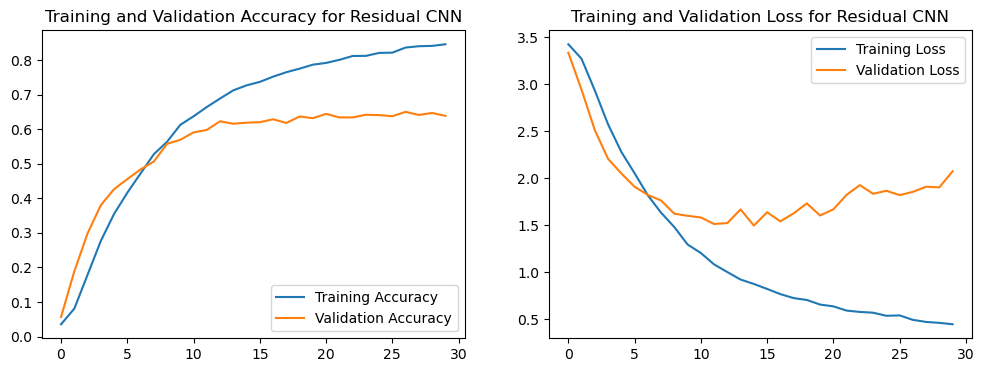

In [ ]:
# plot the training and validation accuracy
acc = history_residual.history['accuracy']
val_acc = history_residual.history['val_accuracy']
loss = history_residual.history['loss']
val_loss = history_residual.history['val_loss']
epochs_range = range(len(acc))
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy for Residual CNN')
plt.legend(loc='lower right')
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss for Residual CNN')
plt.legend(loc='upper right')
plt.show()

## 4. EfficientNet Model with Fine Tuning

###  EfficientNet Model with Fine Tuning - Building the Model

In [ ]:
# 1-1) Build base EfficientNet model
base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(256, 256, 3),
    include_top=False,
    weights='imagenet'
)

# 1-2) Keep the pre-trained model by default
base_model.trainable = False # Freeze the base model


# 2) Fine tune the model by unfreezing the last 20 layers of the base model
for layer in base_model.layers[-20:]:
    layer.trainable = True

# 3) Customise the base model
# 1st - Data augmentation
efficientnet_model_ft = Sequential()
# efficientnet_model_ft.add(RandomFlip('horizontal', input_shape=(256, 256, 3))) # corrected (?)
# efficientnet_model_ft.add(RandomRotation(0.1))
# efficientnet_model_ft.add(RandomZoom(0.1))
# efficientnet_model_ft.add(RandomTranslation(0.1, 0.1))

# 2nd - Base model
efficientnet_model_ft.add(base_model)

# 3rd - Flatten + Dropout + Dense
efficientnet_model_ft.add(GlobalAveragePooling2D())
efficientnet_model_ft.add(Dropout(0.5))
efficientnet_model_ft.add(Dense(30, activation='softmax'))

# 4) Model summary
efficientnet_model_ft.summary()

###  EfficientNet Model with Fine Tuning - Compiling the Model

In [ ]:
# Compile the model
efficientnet_model_ft.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=[
        'accuracy',
        Precision(name='precision'),
        Recall(name='recall'),
        F1Score(name='f1_score', average='macro')
    ]
)

###  EfficientNet Model with Fine Tuning - Training the Model

In [ ]:
# Define early stopping
earlystop_efficientnet_ft = EarlyStopping(patience=5, restore_best_weights=True)

# Define reduce LROn plateau
reduce_lr_efficientnet_ft = ReduceLROnPlateau(patience=3, factor=0.5)

# Combine for callbacks
callbacks_efficientnet_ft = [earlystop_efficientnet_ft, reduce_lr_efficientnet_ft]

# Train the model
# 1) Record memory usage before training
mem_before_efficientnet_ft = psutil.virtual_memory().used

# 2) Record training start time
start_time_efficientnet_ft = time.time()

# 3) Fit the data into efficient model
history_efficientnet_ft = efficientnet_model_ft.fit(
    train,
    validation_data = validation,
    epochs = 20,
    callbacks = callbacks_efficientnet_ft,
    verbose = 1
)

# 4) Record training end time
end_time_efficientnet_ft = time.time()

# 5) Record CPU Usage after training
mem_after_efficientnet_ft = psutil.virtual_memory().used

In [ ]:
# 6) Training Time Used
train_duration_efficientnet_ft = end_time_efficientnet_ft - start_time_efficientnet_ft
print(f"Training Time: {train_duration_efficientnet_ft:.2f} sec")

# 7) Record CPU Usage after training
mem_used_efficientnet_ft = (mem_after_efficientnet_ft  - mem_before_efficientnet_ft) / 1024**2
print(f"Memory Used for Training: {mem_used_efficientnet_ft:.2f} MB（CPU）")

###  EfficientNet Model with Fine Tuning - Evaluating the Model

In [ ]:
# Evaluate the model with test dataset
loss, accuracy, precision, recall, f1_score = efficientnet_model_ft.evaluate(test)
print(f"Test Loss for EfficientNet Model: {loss:.4f}")
print(f"Test Accuracy for EfficientNet CNN Model: {accuracy * 100:.2f}%")
print(f"Test Precision for EfficientNet CNN Model: {precision:.4f}")
print(f"Test Recall for EfficientNet CNN Model: {recall:.4f}")
print(f"Test F1 Score for EfficientNet CNN Model: {f1_score:.4f}")

In [ ]:
# Plot the training and validation accuracy
acc = history_efficientnet_ft.history['accuracy']
val_acc = history_efficientnet_ft.history['val_accuracy']

loss = history_efficientnet_ft.history['loss']
val_loss = history_efficientnet_ft.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Training and Validation Accuracy for EfficientNet with Fine-tuning')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Training and Validation Loss for EfficientNet with Fine-tuning')
plt.legend(loc='upper right')

plt.show()